In [1]:
import os
import random

import wandb

api = wandb.Api()

wandb_project = 'learneddb/lcm'


def get_table_df(url: str, label: str):
    print(url)
    artifact = api.artifact(url)
    artifact.download()

    table = artifact.get(label)
    return table.get_dataframe()


if os.path.exists('wandb_df_cache.pkl'):
    import pickle

    with open('wandb_df_cache.pkl', 'rb') as f:
        df_cache = pickle.load(f)
else:
    df_cache = dict()


def get_dataframes_from_run(run: str):
    if run in df_cache:
        print(f'Found run {run} in cache')
        return df_cache[run]

    if wandb.run is None:
        wandb.init()

    df_dict = {}

    instance = api.run(f'{wandb_project}/{run}')

    for key in instance.summary.keys():
        if key.endswith('pred_table'):
            df_dict[key] = get_table_df(f'{wandb_project}/run-{run}-{key}:latest', key)

    df_cache[run] = df_dict

    # save cache to file
    import pickle
    with open('wandb_df_cache.pkl', 'wb') as f:
        pickle.dump(df_cache, f)

    return df_dict

In [2]:
runs = [
    '8tn6ih3o',
    # 'vyuutioc',
    # 'ivqkjj6c',
    # 'o3vdkq0c',
    # '3w89oh35',
    # '7wfuqhla'
]
run_dict = dict()
for run in runs:
    run_dict[run] = get_dataframes_from_run(run)

Found run 8tn6ih3o in cache


In [3]:
run = runs[0]

df = run_dict[run]['join_order_job_eval_pred_table']
grouped_df = df.groupby('sql')

opt_runtimes = []
picked_runtimes = []
opt_plan_instances = []
picked_plan_instances = []
sqls = []

for sql, group in grouped_df:
    min_runtime = group['label'].min()

    # get the picked plan runtime (the one with the lowest prediction)
    picked_plan = group.loc[group['prediction'].idxmin()]
    picked_plan_runtime = picked_plan['label']

    opt_runtimes.append(min_runtime)
    opt_plan_instances.append(group.loc[group['label'].idxmin()])
    picked_runtimes.append(picked_plan_runtime)
    picked_plan_instances.append(picked_plan)
    sqls.append(sql)

print(f'Optimal runtime: {sum(opt_runtimes)}')
print(f'Picked runtime: {sum(picked_runtimes)}')

Optimal runtime: 156.78919743653387
Picked runtime: 350.7103043195093


## Plot JOB Speedup Overview

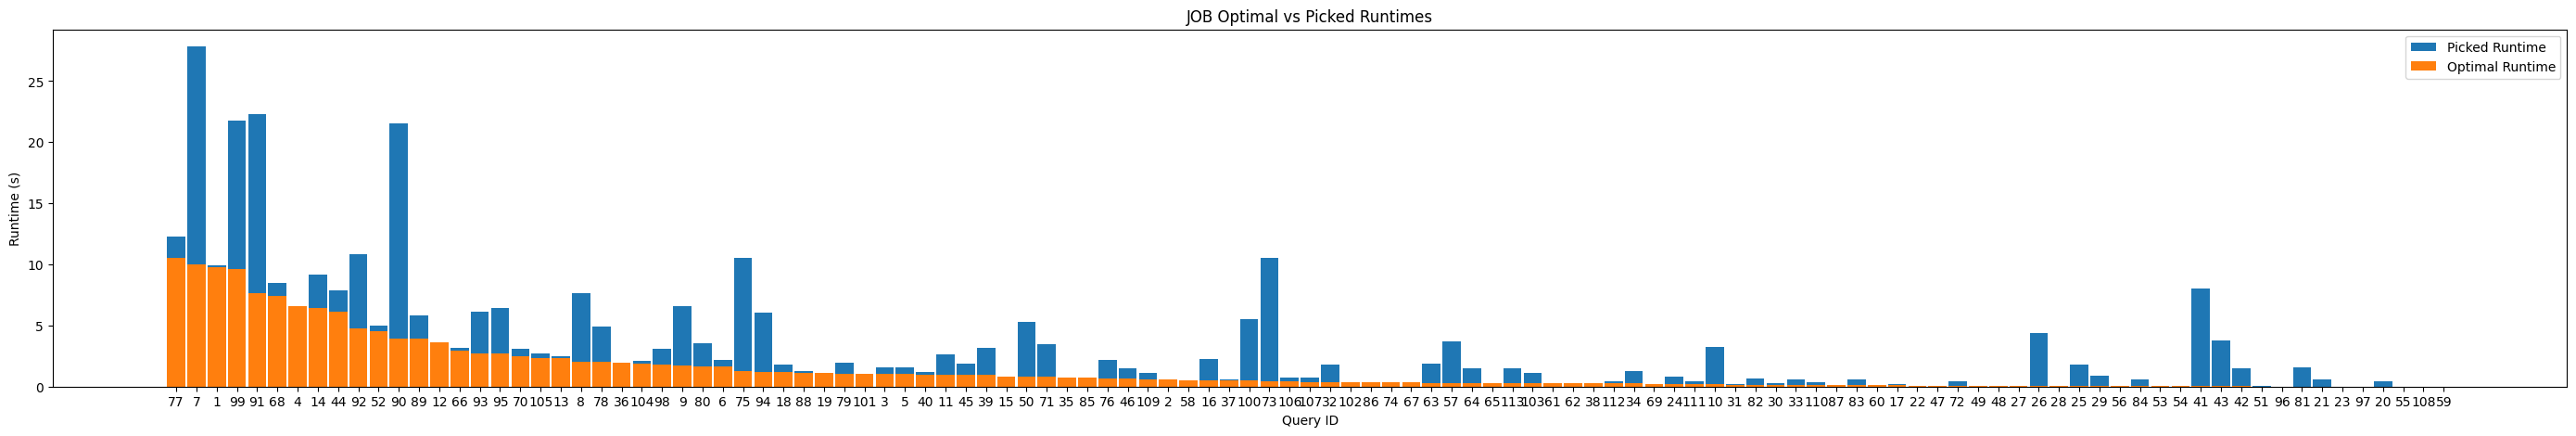

In [4]:
# plot barchart with selected runtime and optimal runtime for each query
import matplotlib.pyplot as plt

q_id = [i for i in range(len(opt_runtimes))]

# sort by opt runtime
sorted_indices = [i for i in sorted(range(len(opt_runtimes)), key=lambda k: opt_runtimes[k], reverse=True)]
opt_runtimes_sorted = [opt_runtimes[i] for i in sorted_indices]
picked_runtimes_sorted = [picked_runtimes[i] for i in sorted_indices]
q_id_sorted = [q_id[i] + 1 for i in sorted_indices]

plt.figure(figsize=(35, 5))
bar_width = 0.9
indices = range(len(opt_runtimes))
plt.bar(indices, picked_runtimes_sorted, width=bar_width, label='Picked Runtime')
plt.bar(indices, opt_runtimes_sorted, width=bar_width, label='Optimal Runtime')
plt.xticks([i for i in indices], q_id_sorted)
plt.legend()
plt.xlabel('Query ID')
plt.ylabel('Runtime (s)')
plt.title('JOB Optimal vs Picked Runtimes')
plt.show()

In [5]:
import json

with open('../../../../ldb_wlexecutor/src/ldb_wlexecutor/analysis/job_analysis.json', 'r') as f:
    job_analysis = json.load(f)


# compute dict mapping job sql query to stats
def extract_info_dicts(analysis):
    query_info = dict()
    query_info_by_id = dict()
    for q in analysis:
        sql = q['query_string']

        # remove newlines and tabs
        sql = sql.replace('\n', ' ').replace('\t', ' ')

        # remove all multiple whitespaces
        sql = ' '.join(sql.split())

        query_info[sql] = q
        query_info_by_id[str(q['query_id'])] = q

    return query_info, query_info_by_id


job_query_info, job_query_info_by_id = extract_info_dicts(job_analysis)

In [6]:
from ipywidgets import interact
import matplotlib


@interact(metric=['dif', 'speedup'],
          highlight=['num_tables', 'num_simple_numeric_filters', 'num_simple_string_filters', 'num_in_filters',
                     'num_like_filters', 'null_filters', 'max_filters_per_table'])
def plot(highlight: str = None, metric: str = 'dif'):
    q_id = [i for i in range(len(opt_runtimes))]

    # sort by opt runtime
    sorted_indices = [i for i in sorted(range(len(opt_runtimes)), key=lambda k: opt_runtimes[k], reverse=True)]
    opt_runtimes_sorted = [opt_runtimes[i] for i in sorted_indices]
    picked_runtimes_sorted = [picked_runtimes[i] for i in sorted_indices]
    sql_sorted = [sqls[i] for i in sorted_indices]

    if metric == 'dif':
        slowdowns = [picked - opt for picked, opt in zip(picked_runtimes_sorted, opt_runtimes_sorted)]
    else:
        slowdowns = [picked / opt for picked, opt in zip(picked_runtimes_sorted, opt_runtimes_sorted)]
    q_id_sorted = [q_id[i] + 1 for i in sorted_indices]

    colors = None
    if highlight is not None:
        colorize_key = [job_query_info[sql][highlight] for sql in sql_sorted]

        # create color map
        cmap = matplotlib.colormaps.get_cmap('autumn_r')
        norm = matplotlib.colors.Normalize(vmin=min(colorize_key), vmax=max(colorize_key))
        colors = cmap(norm(colorize_key))

    # create barchart
    plt.close()
    fig, ax = plt.subplots(figsize=(35, 5))
    bar_width = 0.9
    indices = range(len(opt_runtimes))
    ax.bar(indices, slowdowns, width=bar_width, label='Picked Runtime', color=colors if colors is not None else 'c')
    ax.set_xticks([i for i in indices], q_id_sorted)
    plt.legend()
    plt.xlabel('Query ID')
    plt.ylabel('Runtime (s)' if metric == 'dif' else 'Slowdown')

    if highlight is not None:
        # Add a colorbar for reference
        sm = matplotlib.cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_array([])
        cbar = plt.colorbar(sm, ax=ax)
        cbar.set_label(highlight)

    plt.title('JOB Optimal vs Picked Runtimes')
    plt.show()

interactive(children=(Dropdown(description='highlight', options=('num_tables', 'num_simple_numeric_filters', '…

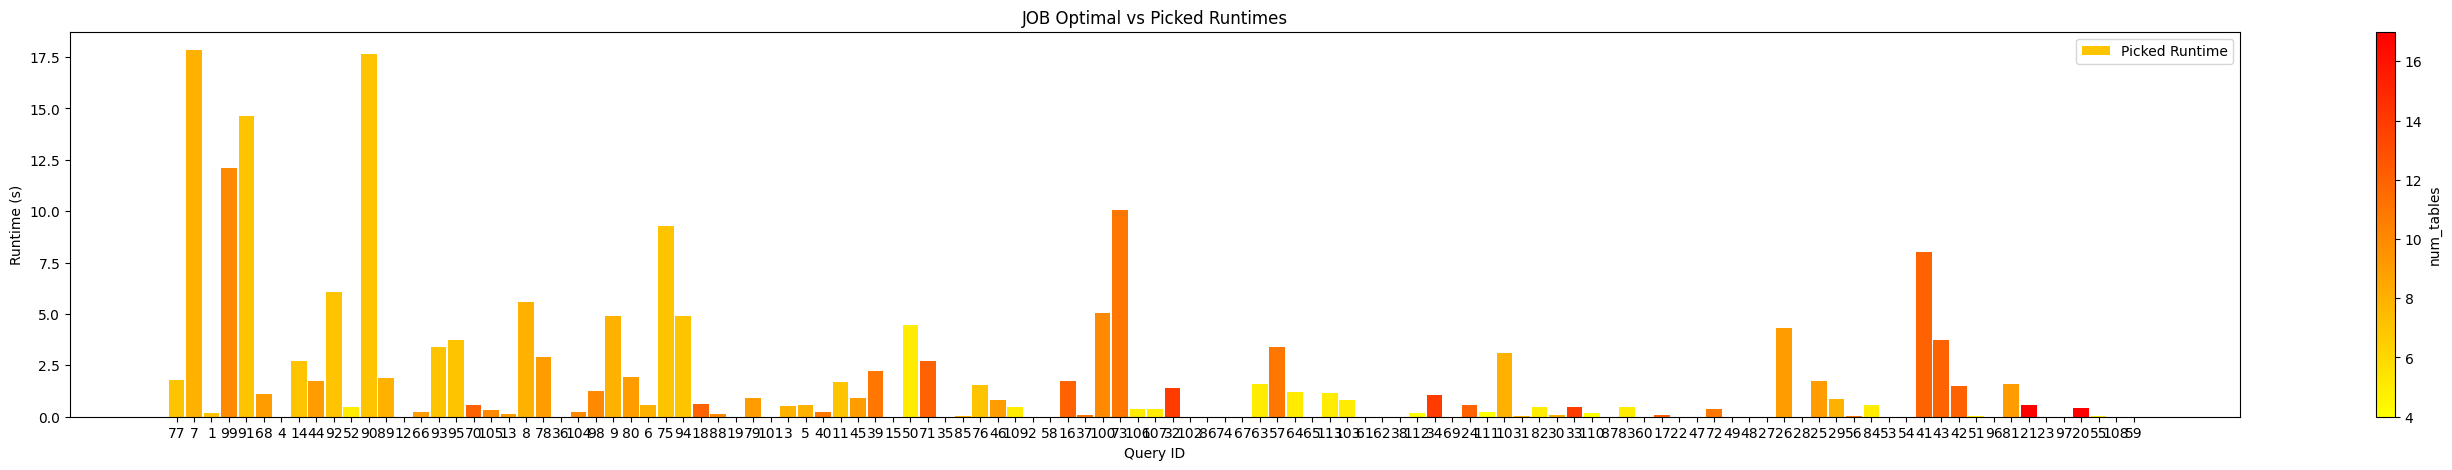

In [7]:
plot('num_tables', 'dif')

### Add to wandb run

In [8]:
append_to_wandb = False
if append_to_wandb:
    print(f'Picked:')
    print(picked_runtimes_sorted[:10])
    print(f'Optimal:')
    print(opt_runtimes_sorted[:10])

    wandb_run = wandb.init(entity='learneddb', project='lcm', id=run, resume='must')
    wandb_run.log(
        {
            "join_order_job_eval_plot": wandb.plot.line_series(
                xs=range(len(opt_runtimes)),
                ys=[opt_runtimes_sorted, picked_runtimes_sorted],
                keys=["Optimal Runtimes", "Picked Runtimes"],
                title="JOB - Picked vs. Optimal Runtimes",
                xname="Query ID",
            ),
        }
    )

## Print Info about query with largest potential

In [9]:
from evaluation.analysis_helper import search_plan, create_explain_dalibo_entry
from tabulate import tabulate

# find idx with highest absolute error
absolute_slowdown = [picked - opt for picked, opt in zip(picked_runtimes, opt_runtimes)]
max_idx = absolute_slowdown.index(max(absolute_slowdown))

print(f'Max absolute slowdown: {absolute_slowdown[max_idx]:.2f}s ({max_idx})')

opt_p = opt_plan_instances[max_idx]
picked_p = picked_plan_instances[max_idx]

# find matching plan
opt_plans, opt_plans_parsed = search_plan(opt_p['sql'], opt_p['hint'])
picked_plans, picked_plans_parsed = search_plan(picked_p['sql'], picked_p['hint'])

assert len(opt_plans) == 1
assert len(picked_plans) == 1

# create dalibo entries
random_id = random.randint(0, 1000)

create_dalibo = False
if create_dalibo:
    opt_url = create_explain_dalibo_entry(opt_p['sql'], opt_plans[0]['analyze_plans'][0], f'{random_id}_Optimal')
    picked_url = create_explain_dalibo_entry(picked_p['sql'], picked_plans[0]['analyze_plans'][0],
                                             f'{random_id}_Picked')
else:
    opt_url = 'not created'
    picked_url = 'not created'

# print stuff
print(opt_p['sql'])
header = ['Val', 'Optimal', 'Picked']
tabulate_rows = [
    ['Runtime', opt_p['label'], picked_p['label']],
    ['Prediction', opt_p['prediction'], picked_p['prediction']],
    ['Absolute Slowdown', '-', absolute_slowdown[max_idx]],
    ['Relative Slowdown', '-', picked_p['label'] / opt_p['label']],
    ['Hint', opt_p['hint'][:20], picked_p['hint']][:20],
    ['Dalibo', opt_url, picked_url]
]
print(tabulate(tabulate_rows, headers=header))

Max absolute slowdown: 17.84s (6)
Loading job file imdb_scaled1/join_order_job_w_idxs_combined.json
Loaded parsed job file imdb_scaled1/join_order_job_w_idxs_combined.json
SELECT MIN(an.name) AS cool_actor_pseudonym, MIN(t.title) AS series_named_after_char FROM aka_name AS an, cast_info AS ci, company_name AS cn, keyword AS k, movie_companies AS mc, movie_keyword AS mk, name AS n, title AS t WHERE cn.country_code ='[us]' AND k.keyword ='character-name-in-title' AND an.person_id = n.id AND n.id = ci.person_id AND ci.movie_id = t.id AND t.id = mk.movie_id AND mk.keyword_id = k.id AND t.id = mc.movie_id AND mc.company_id = cn.id AND an.person_id = ci.person_id AND ci.movie_id = mc.movie_id AND ci.movie_id = mk.movie_id AND mc.movie_id = mk.movie_id;
Val                Optimal               Picked
-----------------  --------------------  ----------------------------------
Runtime            10.003789901733398    27.842493057250977
Prediction         6.949408054351807     0.2255663275718689

In [12]:
print(json.dumps(picked_plans_parsed[0], indent=2))

{
  "plan_parameters": {
    "act_card": 1,
    "act_time": 27842.311,
    "est_card": 1,
    "est_width": 64,
    "pg_cost": 3428.63,
    "op_name": "Simple Aggregate",
    "output_columns": [
      {
        "aggregation": "MIN",
        "columns": [
          {
            "col_id": 40,
            "child_ref": null,
            "table_name": "an",
            "col_name": "name"
          }
        ],
        "udf_name": null,
        "udf_output": "False",
        "child_ref": false
      },
      {
        "aggregation": "MIN",
        "columns": [
          {
            "col_id": 58,
            "child_ref": null,
            "table_name": "t",
            "col_name": "title"
          }
        ],
        "udf_name": null,
        "udf_output": "False",
        "child_ref": false
      }
    ],
    "act_children_card": 3710592,
    "est_children_card": 2897,
    "above_udf_filter": false,
    "is_udf_filter": false
  },
  "children": [
    {
      "plan_parameters": {
        "